# Walmart Retail Sales Analytics and Forecasting

**Goal:** analyse Walmart weekly sales, investigate negative-sales patterns, compare forecasting models, and produce a 12-week company-wide forecast.

This portfolio notebook follows a reproducible workflow:

1. Load and validate the data
2. Explore sales patterns
3. Investigate negative sales
4. Build a time-based forecasting benchmark
5. Compare Linear Regression, Decision Tree, and Random Forest
6. Retrain the winning model and export dashboard-ready data

## 1. Setup and data loading

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid")

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
DATA_DIR = PROJECT_ROOT / "data" / "walmart-recruiting-store-sales-forecasting"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

df = pd.read_csv(DATA_DIR / "train.csv", parse_dates=["Date"])
print(f"Rows: {len(df):,} | Columns: {df.shape[1]}")
display(df.head())

Matplotlib is building the font cache; this may take a moment.


Rows: 421,570 | Columns: 5


,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False


The training data contains weekly department-level sales by store. `Weekly_Sales` is the target; `IsHoliday` identifies special holiday weeks.

In [2]:
data_quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_values": df.isna().sum(),
    "unique_values": df.nunique(),
})
print(f"Duplicate rows: {df.duplicated().sum():,}")
display(data_quality)

Duplicate rows: 0


,dtype,missing_values,unique_values
Store,int64,0,45
Dept,int64,0,81
Date,datetime64[us],0,143
Weekly_Sales,float64,0,359464
IsHoliday,bool,0,2


## 2. Exploratory analysis

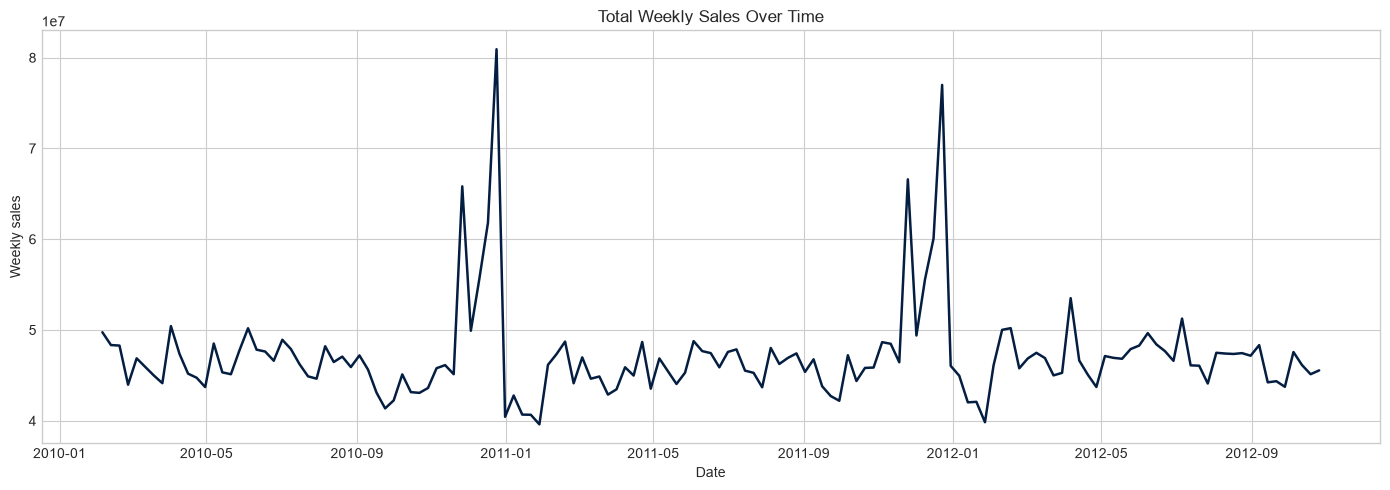

In [3]:
weekly_sales = df.groupby("Date")["Weekly_Sales"].sum().sort_index()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(weekly_sales.index, weekly_sales.values, color="#041E42", linewidth=1.8)
ax.set(
    title="Total Weekly Sales Over Time",
    xlabel="Date",
    ylabel="Weekly sales",
)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "weekly_sales_history.png", dpi=200, bbox_inches="tight")
plt.show()

Weekly sales are usually around 40–50 million, with recurring peaks around Thanksgiving and Christmas. The repeated peaks indicate strong yearly seasonality.

In [4]:
holiday_summary = (
    df.groupby("IsHoliday")["Weekly_Sales"]
      .agg(
          observations="count",
          average_sales="mean",
          median_sales="median",
          total_sales="sum",
      )
      .round(2)
)

top_stores = df.groupby("Store")["Weekly_Sales"].sum().nlargest(10).rename("total_sales")
top_departments = df.groupby("Dept")["Weekly_Sales"].sum().nlargest(10).rename("total_sales")

display(holiday_summary)
display(pd.concat([top_stores, top_departments], axis=1, keys=["Top stores", "Top departments"]))

,observations,average_sales,median_sales,total_sales
IsHoliday,,,,
False,391909,15901.45,7589.95,6.231919e+09
True,29661,17035.82,7947.74,5.052996e+08


,Top stores,Top departments
20,3.013978e+08,NaN
4,2.995440e+08,NaN
14,2.889999e+08,NaN
13,2.865177e+08,1.973216e+08
2,2.753824e+08,2.806112e+08
10,2.716177e+08,NaN
27,2.538559e+08,NaN
6,2.237561e+08,NaN
1,2.224028e+08,NaN
39,2.074455e+08,NaN


## 3. Negative-sales investigation

In [5]:
negative_sales = df[df["Weekly_Sales"] < 0].copy()

negative_overview = pd.Series({
    "negative_records": len(negative_sales),
    "negative_record_rate_pct": len(negative_sales) / len(df) * 100,
    "total_negative_impact": negative_sales["Weekly_Sales"].sum(),
    "median_negative_sale": negative_sales["Weekly_Sales"].median(),
    "largest_negative_sale": negative_sales["Weekly_Sales"].min(),
}).round(2)

display(negative_overview.to_frame("value"))

,value
negative_records,1285.00
negative_record_rate_pct,0.30
total_negative_impact,-88161.56
median_negative_sale,-13.20
largest_negative_sale,-4988.94


In [6]:
selected_departments = [47, 49, 80]
selected_data = df[df["Dept"].isin(selected_departments)].copy()
selected_data["store_group"] = np.where(selected_data["Store"].eq(35), "Store 35", "Other stores")

department_summary = (
    selected_data.groupby("Dept")["Weekly_Sales"]
    .agg(
        total_observations="count",
        negative_observations=lambda x: (x < 0).sum(),
        negative_rate=lambda x: (x < 0).mean() * 100,
        negative_impact=lambda x: x[x < 0].sum(),
    )
    .round(2)
)

store_comparison = (
    selected_data.groupby(["Dept", "store_group"])["Weekly_Sales"]
    .agg(
        total_observations="count",
        negative_observations=lambda x: (x < 0).sum(),
        negative_rate=lambda x: (x < 0).mean() * 100,
        negative_impact=lambda x: x[x < 0].sum(),
    )
    .round(2)
)

display(department_summary)
display(store_comparison)

,total_observations,negative_observations,negative_rate,negative_impact
Dept,,,,
47,646,254,39.32,-53188.06
49,4482,67,1.49,-1455.98
80,5891,68,1.15,-4231.48


total_observations  negative_observations  negative_rate  \
Dept store_group                                                              
47   Other stores                 610                    234          38.36   
     Store 35                      36                     20          55.56   
49   Other stores                4425                     47           1.06   
     Store 35                      57                     20          35.09   
80   Other stores                5757                     43           0.75   
     Store 35                     134                     25          18.66   

                   negative_impact  
Dept store_group                    
47   Other stores        -47994.91  
     Store 35             -5193.15  
49   Other stores          -895.33  
     Store 35              -560.65  
80   Other stores         -2359.84  
     Store 35             -1871.64

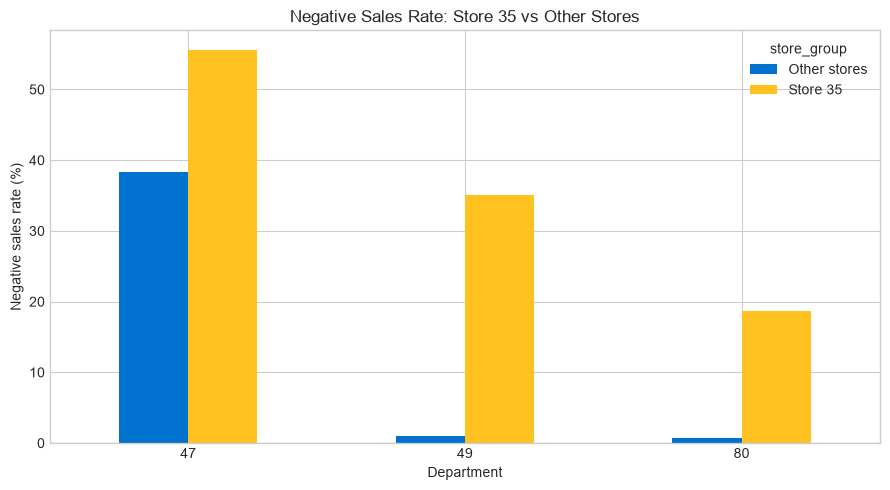

In [7]:
comparison_plot = store_comparison["negative_rate"].unstack("store_group")
ax = comparison_plot.plot(
    kind="bar",
    figsize=(9, 5),
    color={"Other stores": "#0071CE", "Store 35": "#FFC220"},
)
ax.set(
    title="Negative Sales Rate: Store 35 vs Other Stores",
    xlabel="Department",
    ylabel="Negative sales rate (%)",
)
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "store35_negative_sales_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

**Finding:** Department 47 has a broad negative-sales pattern across stores. Departments 49 and 80 are unusually problematic in Store 35, suggesting a store-specific returns, refund, inventory-adjustment, or data-process issue.

In [8]:
dept47 = df[df["Dept"].eq(47)].copy()
dept47["Year"] = dept47["Date"].dt.year

dept47_yearly = (
    dept47.groupby("Year")["Weekly_Sales"]
    .agg(
        total_observations="count",
        negative_observations=lambda x: (x < 0).sum(),
        negative_rate=lambda x: (x < 0).mean() * 100,
        negative_impact=lambda x: x[x < 0].sum(),
    )
    .round(2)
)

dept47_holiday = (
    dept47.groupby("IsHoliday")["Weekly_Sales"]
    .agg(
        total_observations="count",
        negative_observations=lambda x: (x < 0).sum(),
        negative_rate=lambda x: (x < 0).mean() * 100,
    )
    .round(2)
)

display(dept47_yearly)
display(dept47_holiday)

,total_observations,negative_observations,negative_rate,negative_impact
Year,,,,
2010,266,88,33.08,-21670.69
2011,205,86,41.95,-20176.10
2012,175,80,45.71,-11341.27


,total_observations,negative_observations,negative_rate
IsHoliday,,,
False,591,233,39.42
True,55,21,38.18


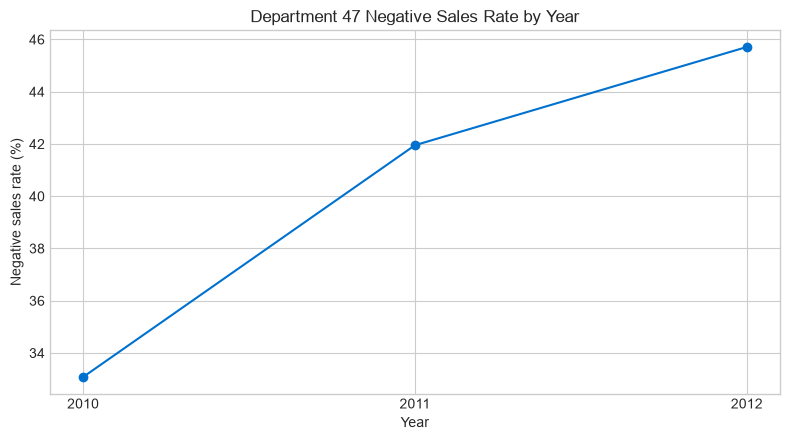

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(dept47_yearly.index, dept47_yearly["negative_rate"], marker="o", color="#0071CE")
ax.set(
    title="Department 47 Negative Sales Rate by Year",
    xlabel="Year",
    ylabel="Negative sales rate (%)",
    xticks=dept47_yearly.index,
)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "dept47_yearly_negative_rate.png", dpi=200, bbox_inches="tight")
plt.show()

Department 47's negative-sales rate increased from about 33% in 2010 to about 46% in 2012. Holiday and non-holiday rates are similar, so holidays do not appear to be the main cause.

## 4. Forecasting setup

In [10]:
test_weeks = 12
train_sales = weekly_sales.iloc[:-test_weeks]
test_sales = weekly_sales.iloc[-test_weeks:]

seasonal_naive_predictions = pd.Series(
    [weekly_sales.get(date - pd.Timedelta(weeks=52), np.nan) for date in test_sales.index],
    index=test_sales.index,
    name="Seasonal Baseline",
)

print(f"Training: {train_sales.index.min().date()} to {train_sales.index.max().date()} ({len(train_sales)} weeks)")
print(f"Testing:  {test_sales.index.min().date()} to {test_sales.index.max().date()} ({len(test_sales)} weeks)")

Training: 2010-02-05 to 2012-08-03 (131 weeks)
Testing:  2012-08-10 to 2012-10-26 (12 weeks)


The split is chronological to prevent future information from leaking into training. The seasonal baseline predicts each test week using sales from the same week one year earlier.

In [11]:
model_data = pd.DataFrame({"Weekly_Sales": weekly_sales})
model_data["Year"] = model_data.index.year
model_data["Month"] = model_data.index.month
model_data["Week"] = model_data.index.isocalendar().week.astype(int)
model_data["Last_Year_Sales"] = model_data["Weekly_Sales"].shift(52)
model_data = model_data.dropna()

features = ["Year", "Month", "Week", "Last_Year_Sales"]
train_model = model_data.iloc[:-test_weeks]
test_model = model_data.iloc[-test_weeks:]

X_train, y_train = train_model[features], train_model["Weekly_Sales"]
X_test, y_test = test_model[features], test_model["Weekly_Sales"]

## 5. Model training and comparison

In [12]:
def regression_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    errors = actual - predicted
    return {
        "MAE": np.mean(np.abs(errors)),
        "RMSE": np.sqrt(np.mean(errors ** 2)),
        "MAPE": np.mean(np.abs(errors / actual)) * 100,
    }


linear_model = LinearRegression().fit(X_train, y_train)
tree_model = DecisionTreeRegressor(max_depth=4, random_state=42).fit(X_train, y_train)
forest_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1,
).fit(X_train, y_train)

predictions = {
    "Seasonal Baseline": seasonal_naive_predictions.values,
    "Linear Regression": linear_model.predict(X_test),
    "Decision Tree": tree_model.predict(X_test),
    "Random Forest": forest_model.predict(X_test),
}

model_results = pd.DataFrame(
    [{"Model": name, **regression_metrics(y_test, pred)} for name, pred in predictions.items()]
).sort_values("MAPE").reset_index(drop=True)

display(model_results.style.format({"MAE": "{:,.0f}", "RMSE": "{:,.0f}", "MAPE": "{:.2f}%"}))

,Model,MAE,RMSE,MAPE
0,Linear Regression,"702,395","890,071",1.53%
1,Random Forest,"718,645","1,116,384",1.57%
2,Seasonal Baseline,"974,642","1,160,987",2.12%
3,Decision Tree,"1,103,849","1,360,534",2.43%


**Model selection:** Linear Regression achieved the lowest MAPE (about 1.53%). It was selected because it was both the most accurate and the easiest model to explain.

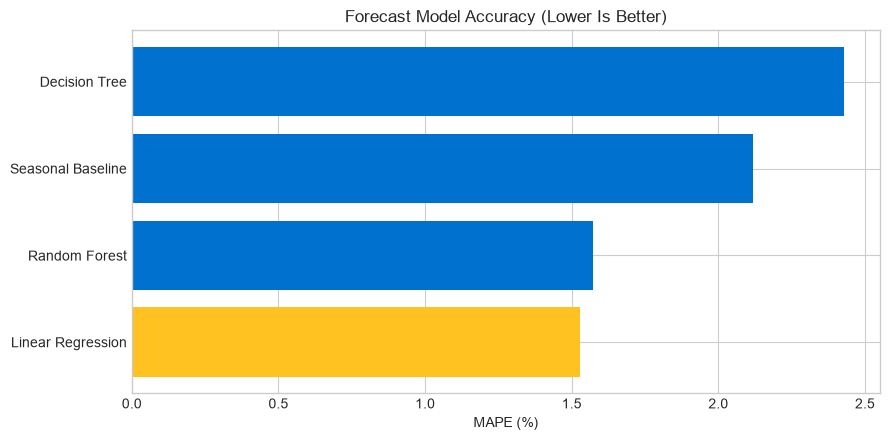

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.5))
plot_results = model_results.sort_values("MAPE", ascending=True)
colors = ["#FFC220" if name == "Linear Regression" else "#0071CE" for name in plot_results["Model"]]
ax.barh(plot_results["Model"], plot_results["MAPE"], color=colors)
ax.set(
    title="Forecast Model Accuracy (Lower Is Better)",
    xlabel="MAPE (%)",
    ylabel="",
)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "model_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

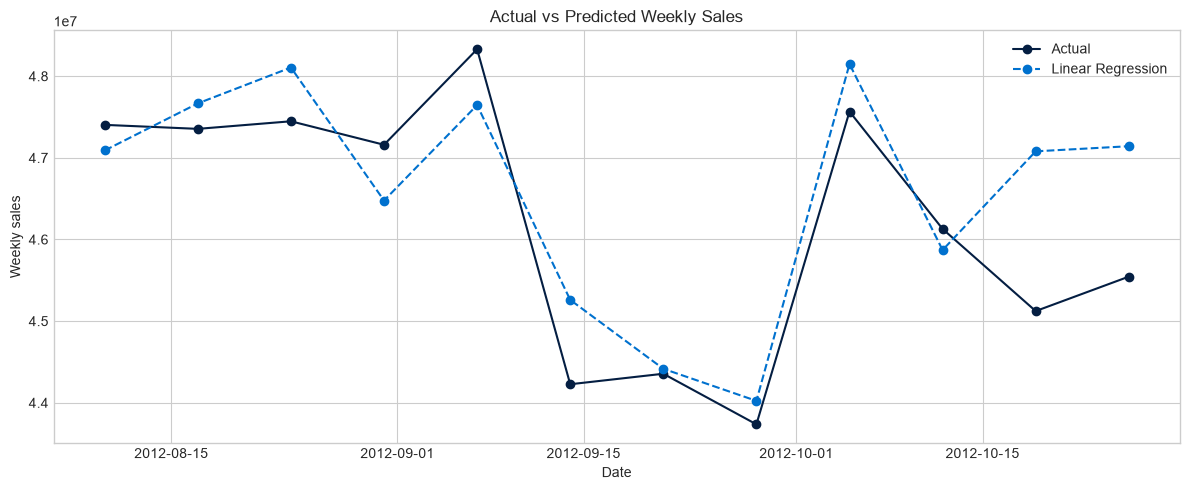

In [14]:
linear_predictions = pd.Series(predictions["Linear Regression"], index=y_test.index)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(y_test.index, y_test, marker="o", label="Actual", color="#041E42")
ax.plot(y_test.index, linear_predictions, marker="o", linestyle="--", label="Linear Regression", color="#0071CE")
ax.set(
    title="Actual vs Predicted Weekly Sales",
    xlabel="Date",
    ylabel="Weekly sales",
)
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "final_model_test_forecast.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Final 12-week forecast and exports

In [15]:
final_model = LinearRegression().fit(model_data[features], model_data["Weekly_Sales"])

future_dates = pd.date_range(
    start=weekly_sales.index.max() + pd.Timedelta(weeks=1),
    periods=12,
    freq="W-FRI",
)
future_data = pd.DataFrame(index=future_dates)
future_data["Year"] = future_data.index.year
future_data["Month"] = future_data.index.month
future_data["Week"] = future_data.index.isocalendar().week.astype(int)
future_data["Last_Year_Sales"] = [
    weekly_sales.get(date - pd.Timedelta(weeks=52)) for date in future_dates
]

assert not future_data[features].isna().any().any(), "Future features contain missing values"

future_forecast = pd.DataFrame({
    "Date": future_dates,
    "Predicted_Weekly_Sales": final_model.predict(future_data[features]),
})
display(future_forecast.style.format({"Predicted_Weekly_Sales": "{:,.0f}"}))

,Date,Predicted_Weekly_Sales
0,2012-11-02 00:00:00,"49,331,667"
1,2012-11-09 00:00:00,"49,210,696"
2,2012-11-16 00:00:00,"47,568,608"
3,2012-11-23 00:00:00,"64,132,978"
4,2012-11-30 00:00:00,"50,045,931"
5,2012-12-07 00:00:00,"55,142,898"
6,2012-12-14 00:00:00,"58,883,022"
7,2012-12-21 00:00:00,"72,787,314"
8,2012-12-28 00:00:00,"47,416,354"
9,2013-01-04 00:00:00,"45,037,320"


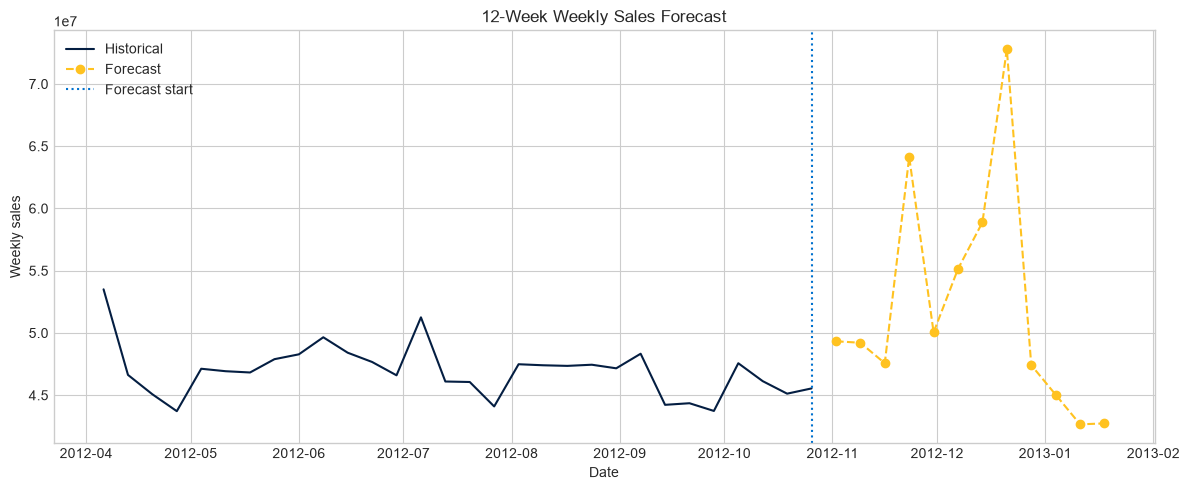

In [16]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(weekly_sales.tail(30).index, weekly_sales.tail(30), label="Historical", color="#041E42")
ax.plot(
    future_forecast["Date"],
    future_forecast["Predicted_Weekly_Sales"],
    marker="o",
    linestyle="--",
    label="Forecast",
    color="#FFC220",
)
ax.axvline(weekly_sales.index.max(), color="#0071CE", linestyle=":", label="Forecast start")
ax.set(
    title="12-Week Weekly Sales Forecast",
    xlabel="Date",
    ylabel="Weekly sales",
)
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "future_12_week_forecast.png", dpi=200, bbox_inches="tight")
plt.show()

In [17]:
historical_export = weekly_sales.rename("Weekly_Sales").reset_index()
historical_export["Data_Type"] = "Historical"

forecast_export = future_forecast.rename(columns={"Predicted_Weekly_Sales": "Weekly_Sales"})
forecast_export["Data_Type"] = "Forecast"

powerbi_sales_data = pd.concat([historical_export, forecast_export], ignore_index=True)

department_summary.to_csv(OUTPUT_DIR / "department_summary.csv")
store_comparison.to_csv(OUTPUT_DIR / "store35_vs_other_stores.csv")
dept47_yearly.to_csv(OUTPUT_DIR / "dept47_yearly_summary.csv")
model_results.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)
future_forecast.to_csv(OUTPUT_DIR / "future_12_week_forecast.csv", index=False)
powerbi_sales_data.to_csv(OUTPUT_DIR / "powerbi_sales_forecast.csv", index=False)

with pd.ExcelWriter(OUTPUT_DIR / "walmart_powerbi_dashboard.xlsx", engine="openpyxl") as writer:
    powerbi_sales_data.to_excel(writer, sheet_name="Sales_Forecast", index=False)
    model_results.to_excel(writer, sheet_name="Model_Results", index=False)
    store_comparison.reset_index().to_excel(writer, sheet_name="Negative_Sales", index=False)
    dept47_yearly.reset_index().to_excel(writer, sheet_name="Dept47_Yearly", index=False)

print(f"Saved final outputs to: {OUTPUT_DIR}")

Saved final outputs to: /Users/zoolutanwar/Desktop/Retail-Analytics-Project/outputs


## 7. Business conclusions

- Walmart sales display strong annual holiday seasonality, with major Thanksgiving and Christmas peaks.
- Department 47 shows a widespread negative-sales pattern that is not meaningfully explained by holiday weeks.
- Departments 49 and 80 have unusually high negative-sales rates in Store 35, warranting a store-specific review of returns, refunds, inventory adjustments, and data-entry processes.
- Linear Regression produced the best 12-week holdout performance with approximately **1.53% MAPE**, narrowly beating Random Forest and outperforming the seasonal baseline.
- The final 12-week forecast predicts holiday peaks followed by the expected post-holiday decline.

### Limitations

- Negative sales may represent valid returns or accounting corrections; the dataset does not identify their exact cause.
- Model evaluation uses a single 12-week holdout period. Rolling time-series validation would provide a stronger estimate of generalisation.
- This model forecasts company-wide weekly sales. Store-department-level forecasting would be the next extension.